# Retraining the LSTM Email Phishing Detection Model with Adversarial Examples

We will retrain the LSTM phishing detection model by combining:
- Original phishing email dataset
- Successful adversarial phishing examples

This improves robustness against future adversarial attacks.


## 1. Import Required Libraries


In [23]:
import pandas as pd
import numpy as np
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
import re


## 2. Define Text Preprocessing Function


In [24]:
def preprocess_text(text):
    text = re.sub(r'http\S+', '', text)  # Remove URLs
    text = re.sub(r'[^\w\s]', '', text)  # Remove punctuation
    text = text.lower()  # Lowercase text
    text = re.sub(r'\s+', ' ', text).strip()  # Remove extra spaces
    return text


## 3. Load and Clean Original Dataset


In [25]:
original_data_file = r"C:\Users\USER\Ola_Adv_phishing\Data\raw\Phishing_Email.csv"

df_original = pd.read_csv(original_data_file)
df_original.drop(["Unnamed: 0"], axis=1, inplace=True)
df_original.dropna(inplace=True)
df_original.drop_duplicates(inplace=True)

df_original.head()


,Email Text,Email Type
0,"re : 6 . 1100 , disc : uniformitarianism , re ...",Safe Email
1,the other side of * galicismos * * galicismo *...,Safe Email
2,re : equistar deal tickets are you still avail...,Safe Email
3,\nHello I am your hot lil horny toy.\n I am...,Phishing Email
4,software at incredibly low prices ( 86 % lower...,Phishing Email


## 4. Load and Prepare Adversarial Dataset


In [26]:
adversarial_data_file = r"C:\Users\USER\Ola_Adv_phishing\Data\adversary\successful_adversarial_examples.csv"

df_adversarial = pd.read_csv(adversarial_data_file)

# Keep only perturbed text and correct labels
df_adversarial_filtered = df_adversarial[['perturbed_text', 'ground_truth_output']].copy()
df_adversarial_filtered.rename(columns={
    'perturbed_text': 'Email Text',
    'ground_truth_output': 'Email Type'
}, inplace=True)

# Map numeric labels to original string labels
label_mapping = {0: 'Phishing Email', 1: 'Safe Email'}
df_adversarial_filtered['Email Type'] = df_adversarial_filtered['Email Type'].map(label_mapping)

df_adversarial_filtered.head()


,Email Text,Email Type
0,re 6 1100 disc uniformitarianism re 1086 sex l...,Safe Email
1,[[hXello]] i am your [[ot]] [[Oil]] [[bhorny]]...,Phishing Email
2,on sun [[ag]] [[1]] [[002]] at 111747am [[000]...,Safe Email


## 5. Combine Datasets and Preprocess


In [27]:
# Combine datasets
df_combined = pd.concat([df_original, df_adversarial_filtered], ignore_index=True)
df_combined.dropna(inplace=True)
df_combined.drop_duplicates(inplace=True)

# Clean text
df_combined["Email Text"] = df_combined["Email Text"].apply(preprocess_text)

# Encode labels
le = LabelEncoder()
df_combined["Email Type"] = le.fit_transform(df_combined["Email Type"])

df_combined.head()


,Email Text,Email Type
0,re 6 1100 disc uniformitarianism re 1086 sex l...,1
1,the other side of galicismos galicismo is a sp...,1
2,re equistar deal tickets are you still availab...,1
3,hello i am your hot lil horny toy i am the one...,0
4,software at incredibly low prices 86 lower dra...,0


## 6. Split Data and Tokenize


In [30]:
X = df_combined["Email Text"]
y = df_combined["Email Type"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Tokenizer
tokenizer = Tokenizer()
tokenizer.fit_on_texts(X_train)
max_len = 150

# Vocabulary size (add 1 for padding token 0)
vocab_size = len(tokenizer.word_index) + 1
print("Vocab size:", vocab_size)


X_train_seq = tokenizer.texts_to_sequences(X_train)
X_test_seq = tokenizer.texts_to_sequences(X_test)

X_train_padded = pad_sequences(X_train_seq, padding='post', maxlen=max_len)
X_test_padded = pad_sequences(X_test_seq, padding='post', maxlen=max_len)


Vocab size: 163900


## 7. Reconstruct LSTM Architecture to be used for the Adversarial Inputs - to retrain it jsutlike the intial model


In [31]:
from tensorflow.keras.utils import to_categorical

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, Bidirectional, LSTM, Dense, Dropout
from tensorflow.keras.optimizers import Adam

model = Sequential()
model.add(Embedding(input_dim=vocab_size, output_dim=50, input_length=max_len))
model.add(Bidirectional(LSTM(units=64)))
model.add(Dense(32, activation='relu'))
model.add(Dropout(0.5))
model.add(Dense(1, activation='sigmoid'))


C:\Users\USER\anaconda3\envs\adversary\lib\site-packages\keras\src\layers\core\embedding.py:97: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


In [32]:
model.compile(loss='binary_crossentropy', optimizer=Adam(learning_rate=1e-3), metrics=['accuracy'])

In [33]:
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ embedding (Embedding)                │ ?                           │     0 (unbuilt) │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ bidirectional (Bidirectional)        │ ?                           │     0 (unbuilt) │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ ?                           │     0 (unbuilt) │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ ?                           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ ?                           │     0 (unbuilt) │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

## 8. Retrain Model with Combined Dataset


In [34]:
history = model.fit(
    X_train_padded, y_train,
    epochs=5, batch_size=32,
    validation_data=(X_test_padded, y_test),
    verbose=1
)


Epoch 1/5
439/439 ━━━━━━━━━━━━━━━━━━━━ 91s 192ms/step - accuracy: 0.9108 - loss: 0.2166 - val_accuracy: 0.9678 - val_loss: 0.0984
Epoch 2/5
439/439 ━━━━━━━━━━━━━━━━━━━━ 84s 192ms/step - accuracy: 0.9892 - loss: 0.0396 - val_accuracy: 0.9724 - val_loss: 0.0923
Epoch 3/5
439/439 ━━━━━━━━━━━━━━━━━━━━ 88s 200ms/step - accuracy: 0.9951 - loss: 0.0199 - val_accuracy: 0.9706 - val_loss: 0.1230
Epoch 4/5
439/439 ━━━━━━━━━━━━━━━━━━━━ 91s 207ms/step - accuracy: 0.9979 - loss: 0.0080 - val_accuracy: 0.9641 - val_loss: 0.1188
Epoch 5/5
439/439 ━━━━━━━━━━━━━━━━━━━━ 86s 195ms/step - accuracy: 0.9981 - loss: 0.0074 - val_accuracy: 0.9692 - val_loss: 0.1436


## 9. Save Updated Model and Tokenizer


In [36]:
import pickle

new_model_file = r"C:\Users\USER\Ola_Adv_phishing\models\retrained_lstm_email_classifier.h5"
model.save(new_model_file)
print(f"New robust model saved to {new_model_file}")

with open(r'C:\Users\USER\Ola_Adv_phishing\models\retrained_tokenizer.pickle', 'wb') as handle:
    pickle.dump(tokenizer, handle, protocol=pickle.HIGHEST_PROTOCOL)
print("Tokenizer saved to tokenizer.pickle")


New robust model saved to C:\Users\USER\Ola_Adv_phishing\models\retrained_lstm_email_classifier.h5
Tokenizer saved to tokenizer.pickle


## **| Performance

In [38]:
# Evaluate using padded sequences
results = model.evaluate(X_test_padded, y_test)

loss, accuracy = results[0], results[1]

print(f"Model Loss: {loss}")
print(f"Model Accuracy: {accuracy*100:.2f}%")


110/110 ━━━━━━━━━━━━━━━━━━━━ 3s 29ms/step - accuracy: 0.9692 - loss: 0.1436
Model Loss: 0.14364418387413025
Model Accuracy: 96.92%


In [40]:
y_pred_prob = model.predict(X_test_padded)
y_pred = (y_pred_prob > 0.5).astype(int)

110/110 ━━━━━━━━━━━━━━━━━━━━ 4s 35ms/step


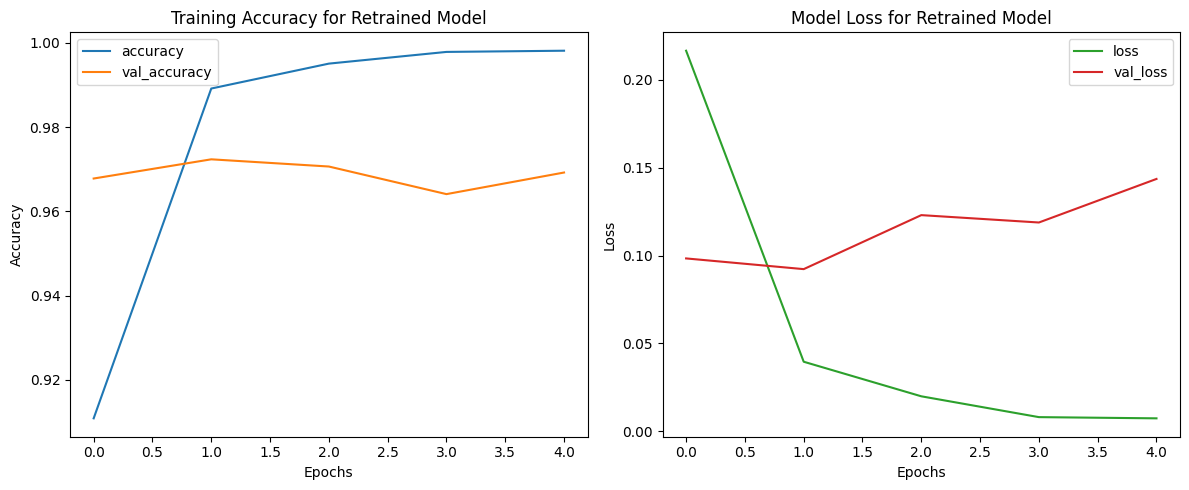

In [51]:
import matplotlib.pyplot as plt
import pandas as pd

# Convert history to DataFrame
history_df = pd.DataFrame(history.history)

# Create subplots (1 row, 2 columns)
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Accuracy plot with custom colors
history_df[['accuracy', 'val_accuracy']].plot(
    ax=axes[0],
    color=['#1f77b4', '#ff7f0e']  # Blue & Orange
)
axes[0].set_title('Training Accuracy for Retrained Model')
axes[0].set_xlabel('Epochs')
axes[0].set_ylabel('Accuracy')

# Loss plot with custom colors
history_df[['loss', 'val_loss']].plot(
    ax=axes[1],
    color=['#2ca02c', '#d62728']  # Green & Red
)
axes[1].set_title('Model Loss for Retrained Model')
axes[1].set_xlabel('Epochs')
axes[1].set_ylabel('Loss')

# Adjust layout
plt.tight_layout()
plt.show()


#### Classifcation Report

In [48]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report

# Predictions
y_pred_prob = model.predict(X_test_padded)
y_pred = (y_pred_prob > 0.5).astype(int)

# Metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print(f"Accuracy: {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1 Score: {f1:.4f}")

# Detailed report
print("\nClassification Report for Retrained Model:\n", classification_report(y_test, y_pred))


110/110 ━━━━━━━━━━━━━━━━━━━━ 4s 34ms/step
Accuracy: 0.9692
Precision: 0.9733
Recall: 0.9777
F1 Score: 0.9755

Classification Report for Retrained Model:
               precision    recall  f1-score   support

           0       0.96      0.96      0.96      1312
           1       0.97      0.98      0.98      2197

    accuracy                           0.97      3509
   macro avg       0.97      0.97      0.97      3509
weighted avg       0.97      0.97      0.97      3509



#####################################

#### Confusion Matrix

######################################

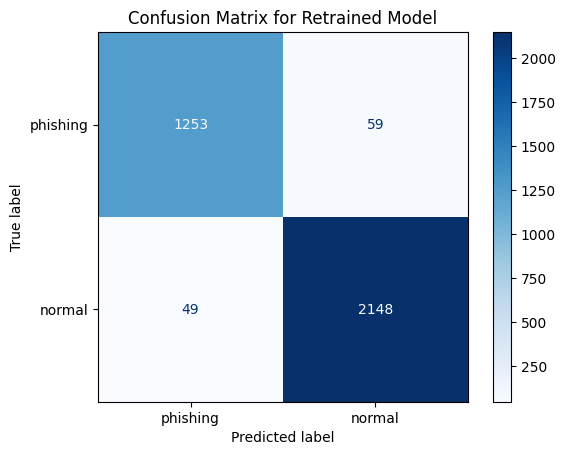

In [49]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cnf = confusion_matrix(y_test, y_pred)

# Display with a different color map
disp = ConfusionMatrixDisplay(confusion_matrix=cnf, display_labels=['phishing', 'normal'])
disp.plot(cmap=plt.cm.Blues)  # You can try plt.cm.Greens, plt.cm.Oranges, etc.
plt.title("Confusion Matrix for Retrained Model")
plt.show()


AUC Score: 0.9950


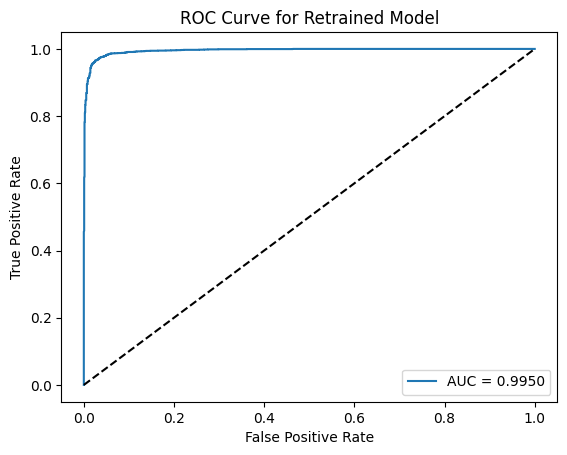

In [50]:
auc_score = roc_auc_score(y_test, y_pred_prob)
fpr, tpr, thresholds = roc_curve(y_test, y_pred_prob)

print(f"AUC Score: {auc_score:.4f}")

plt.figure()
plt.plot(fpr, tpr, label=f"AUC = {auc_score:.4f}")
plt.plot([0, 1], [0, 1], 'k--')  # Diagonal reference line
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve for Retrained Model')
plt.legend(loc='lower right')
plt.show()